In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("D:/load_forecasting_dataset_200_rows-1.csv")

In [4]:
df.head()

,Timestamp,Temperature (°C),Humidity (%),Wind Speed (m/s),Rainfall (mm),Solar Irradiance (W/m²),GDP (LKR),Per Capita Energy Use (kWh),Electricity Price (LKR/kWh),Day of Week,Hour of Day,Month,Season,Public Event,Load Demand (kW)
0,2020-01-01 00:00:00,28.63,65.40,3.82,1.37,0.0,850000.00,1196.58,40.86,Wednesday,0,1,Winter,No,1053.75
1,2020-01-01 00:15:00,29.38,67.86,2.51,2.37,0.0,850025.13,1224.56,40.17,Wednesday,0,1,Winter,Yes,1017.46
2,2020-01-01 00:30:00,27.74,71.32,4.73,0.55,0.0,850050.25,1209.01,40.86,Wednesday,0,1,Winter,No,1060.30
3,2020-01-01 00:45:00,27.97,67.44,2.45,0.44,0.0,850075.38,1215.26,40.43,Wednesday,0,1,Winter,No,1063.90
4,2020-01-01 01:00:00,24.95,72.08,2.44,0.00,0.0,850100.50,1194.23,41.03,Wednesday,1,1,Winter,No,991.22


In [5]:
print(df.isnull().sum())

Timestamp                      0
Temperature (°C)               0
Humidity (%)                   0
Wind Speed (m/s)               0
Rainfall (mm)                  0
Solar Irradiance (W/m²)        0
GDP (LKR)                      0
Per Capita Energy Use (kWh)    0
Electricity Price (LKR/kWh)    0
Day of Week                    0
Hour of Day                    0
Month                          0
Season                         0
Public Event                   0
Load Demand (kW)               0
dtype: int64


In [6]:
df = df.dropna()

print(df.isnull().sum())

Timestamp                      0
Temperature (°C)               0
Humidity (%)                   0
Wind Speed (m/s)               0
Rainfall (mm)                  0
Solar Irradiance (W/m²)        0
GDP (LKR)                      0
Per Capita Energy Use (kWh)    0
Electricity Price (LKR/kWh)    0
Day of Week                    0
Hour of Day                    0
Month                          0
Season                         0
Public Event                   0
Load Demand (kW)               0
dtype: int64


In [7]:
df = df.fillna(0)

print(df.isnull().sum())

Timestamp                      0
Temperature (°C)               0
Humidity (%)                   0
Wind Speed (m/s)               0
Rainfall (mm)                  0
Solar Irradiance (W/m²)        0
GDP (LKR)                      0
Per Capita Energy Use (kWh)    0
Electricity Price (LKR/kWh)    0
Day of Week                    0
Hour of Day                    0
Month                          0
Season                         0
Public Event                   0
Load Demand (kW)               0
dtype: int64


In [8]:
print(df.duplicated())

0      False
1      False
2      False
3      False
4      False
       ...  
195    False
196    False
197    False
198    False
199    False
Length: 200, dtype: bool


In [9]:
print("Duplicate count:", df.duplicated().sum())

Duplicate count: 0


In [10]:
df = df.drop_duplicates()

print("After removing duplicates:", df.shape)

After removing duplicates: (200, 15)


In [11]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

print(df['Timestamp'].dtype)

datetime64[us]


In [12]:
df.head()

,Timestamp,Temperature (°C),Humidity (%),Wind Speed (m/s),Rainfall (mm),Solar Irradiance (W/m²),GDP (LKR),Per Capita Energy Use (kWh),Electricity Price (LKR/kWh),Day of Week,Hour of Day,Month,Season,Public Event,Load Demand (kW)
0,2020-01-01 00:00:00,28.63,65.40,3.82,1.37,0.0,850000.00,1196.58,40.86,Wednesday,0,1,Winter,No,1053.75
1,2020-01-01 00:15:00,29.38,67.86,2.51,2.37,0.0,850025.13,1224.56,40.17,Wednesday,0,1,Winter,Yes,1017.46
2,2020-01-01 00:30:00,27.74,71.32,4.73,0.55,0.0,850050.25,1209.01,40.86,Wednesday,0,1,Winter,No,1060.30
3,2020-01-01 00:45:00,27.97,67.44,2.45,0.44,0.0,850075.38,1215.26,40.43,Wednesday,0,1,Winter,No,1063.90
4,2020-01-01 01:00:00,24.95,72.08,2.44,0.00,0.0,850100.50,1194.23,41.03,Wednesday,1,1,Winter,No,991.22


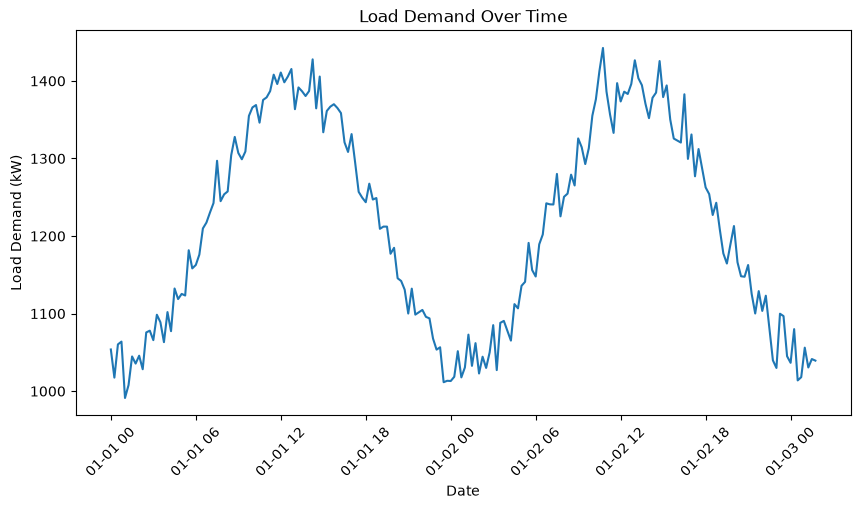

In [13]:
plt.figure(figsize=(10,5))

plt.plot(df['Timestamp'], df['Load Demand (kW)'])

plt.xlabel("Date")
plt.ylabel("Load Demand (kW)")
plt.title("Load Demand Over Time")

plt.xticks(rotation=45)
plt.show()

In [14]:
df['Moving Average'] = df['Load Demand (kW)'].rolling(window=5).mean()

print(df[['Timestamp', 'Load Demand (kW)', 'Moving Average']].head(10))

            Timestamp  Load Demand (kW)  Moving Average
0 2020-01-01 00:00:00           1053.75             NaN
1 2020-01-01 00:15:00           1017.46             NaN
2 2020-01-01 00:30:00           1060.30             NaN
3 2020-01-01 00:45:00           1063.90             NaN
4 2020-01-01 01:00:00            991.22        1037.326
5 2020-01-01 01:15:00           1007.83        1028.142
6 2020-01-01 01:30:00           1044.74        1033.598
7 2020-01-01 01:45:00           1035.55        1028.648
8 2020-01-01 02:00:00           1045.71        1025.010
9 2020-01-01 02:15:00           1028.23        1032.412


In [15]:
df['Trend'] = df['Load Demand (kW)'].diff()

increase = (df['Trend'] > 0).sum()

print("Increasing Trend Count:", increase)

Increasing Trend Count: 100


In [16]:
decrease = (df['Trend'] < 0).sum()

print("Decreasing Trend Count:", decrease)

Decreasing Trend Count: 99


In [17]:
stable = ((df['Trend'] >= -5) & (df['Trend'] <= 5)).sum()

print("Stable Trend Count:", stable)

Stable Trend Count: 31
